<a id="secao-9"></a>

## 9. Modelagem preditiva — validação temporal e cenário exploratório

A previsão usa somente SIA, cuja série está completa. SIH não é modelado porque novembro/dezembro de 2025 exigem investigação de maturidade. Há somente 24 competências; portanto, a projeção é didática e exploratória, não operacional.

**Modelos candidatos:** média móvel de três meses, tendência linear e ingênuo sazonal (mesmo mês do ano anterior). A validação é de origem móvel: cada mês de 2025 é previsto apenas com competências anteriores. O melhor modelo é o de menor MAPE; em empate, menor MAE.

São 12 previsões de um mês à frente, com histórico crescente. O MAPE dessa janela não valida os 12 meses projetados a partir de dezembro de 2025. A seleção e a avaliação usam a mesma janela, sem teste final independente. A cobertura das competências SIA não comprova encerramento administrativo ou ausência de revisões.

### 9.1 Métodos candidatos

| Método | Regra de previsão | Papel didático |
|---|---|---|
| Média móvel de três meses | Média dos três valores mais recentes | Referência de nível local. |
| Tendência linear | Regressão do total mensal contra o índice de tempo | Extrapolação de tendência. |
| Ingênuo sazonal | Valor do mesmo mês do ano anterior | Referência sazonal. |

### 9.2 Validação de origem móvel e métricas de erro

**Procedimento:** gerar 12 previsões de um mês à frente para 2025, treinando somente nos meses anteriores. Comparar MAE (erro absoluto médio), RMSE (raiz do erro quadrático médio) e MAPE (erro percentual absoluto médio). Valores menores indicam menores erros nesta janela. A seleção usa MAPE e MAE como desempate; não é um teste de superioridade estatística.

**Leitura da saída:** a tendência linear apresentou o menor MAPE (3,01%) entre os três candidatos na validação realizada, sem garantir precisão de uma projeção anual.

In [17]:
sia_mensal = serie_brasil[['data', 'sia']].sort_values('data').reset_index(drop=True)
serie_completa = sia_mensal['sia'].to_numpy(dtype=float)

def previsao_media_movel(serie, horizonte, janela=3):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = np.mean(historico[-janela:])
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

def previsao_tendencia_linear(serie, horizonte):
    x = np.arange(len(serie))
    inclinacao, intercepto = np.polyfit(x, serie, 1)
    return intercepto + inclinacao * np.arange(len(serie), len(serie) + horizonte)

def previsao_sazonal_ingenua(serie, horizonte):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = historico[-12]
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

geradores = {
    'Média móvel (3 meses)': previsao_media_movel,
    'Tendência linear': previsao_tendencia_linear,
    'Ingênuo sazonal': previsao_sazonal_ingenua,
}
previsoes_validacao = {modelo: [] for modelo in geradores}
observados_validacao = []
for indice in range(12, len(serie_completa)):
    historico = serie_completa[:indice]
    observados_validacao.append(serie_completa[indice])
    for modelo, gerador in geradores.items():
        previsoes_validacao[modelo].append(gerador(historico, 1)[0])

observados_validacao = np.array(observados_validacao)

metricas = []
for modelo, previsao in previsoes_validacao.items():
    erro = observados_validacao - np.array(previsao)
    metricas.append({'modelo': modelo, 'MAE': np.mean(np.abs(erro)), 'RMSE': sqrt(np.mean(erro ** 2)), 'MAPE_pct': 100 * np.mean(np.abs(erro / observados_validacao))})
metricas = pd.DataFrame(metricas).sort_values(['MAPE_pct', 'MAE']).reset_index(drop=True)
melhor_modelo = metricas.loc[0, 'modelo']
display(metricas.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE_pct': '{:.2f}%'}).highlight_min(subset=['MAE', 'RMSE', 'MAPE_pct'], color='#D9EAD3'))
print(f'Modelo selecionado: {melhor_modelo}. Critério: menor MAPE e, em empate, menor MAE.')

,modelo,MAE,RMSE,MAPE_pct
0,Tendência linear,"46,849","62,453",3.01%
1,Média móvel (3 meses),"55,276","65,864",3.53%
2,Ingênuo sazonal,"57,400","65,882",3.59%


Modelo selecionado: Tendência linear. Critério: menor MAPE e, em empate, menor MAE.


### 9.3 Cenário ilustrativo de 2026 — extrapolação do modelo selecionado

**Procedimento:** ajustar a regra selecionada aos 24 meses de 2024–2025 e gerar 12 valores a partir do corte de dezembro/2025.

**Interpretação:** a tabela e a linha tracejada representam um cenário didático. A validação anterior cobre um mês à frente, não o horizonte anual; não há observações de 2026 nesta base nem intervalo preditivo calibrado. O cenário não é previsão operacional ou atualizada na data de redação.

,mes,previsao_sia
0,01/2026,"1,625,257"
1,02/2026,"1,630,955"
2,03/2026,"1,636,653"
3,04/2026,"1,642,351"
4,05/2026,"1,648,048"
5,06/2026,"1,653,746"
6,07/2026,"1,659,444"
7,08/2026,"1,665,142"
8,09/2026,"1,670,839"
9,10/2026,"1,676,537"


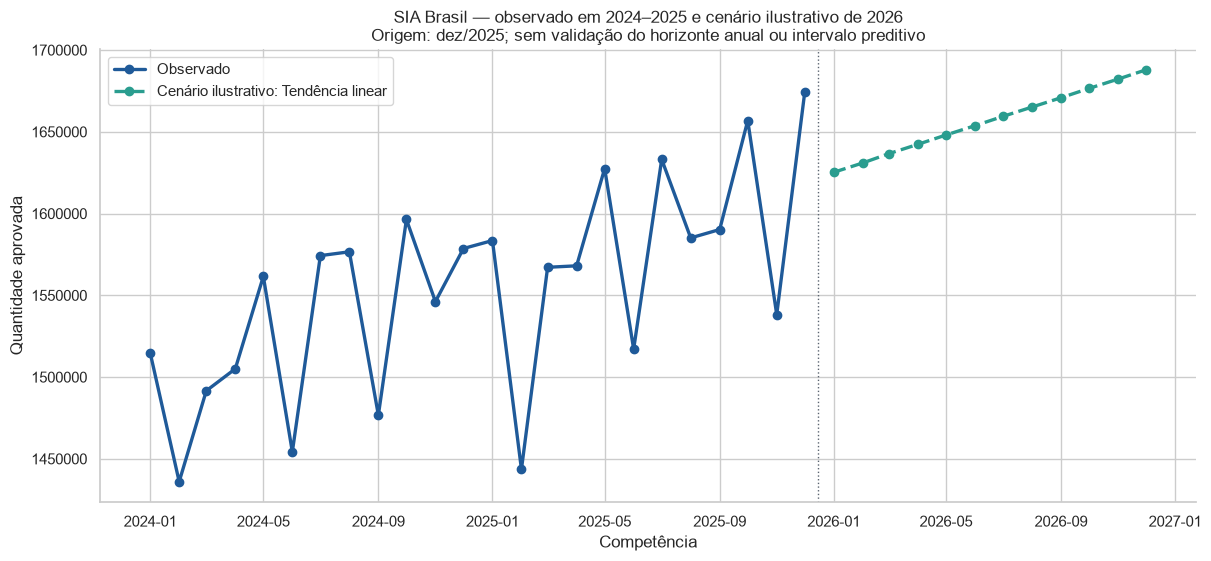

In [18]:
if melhor_modelo == 'Média móvel (3 meses)':
    previsao_2026 = previsao_media_movel(serie_completa, 12)
elif melhor_modelo == 'Tendência linear':
    previsao_2026 = previsao_tendencia_linear(serie_completa, 12)
else:
    previsao_2026 = previsao_sazonal_ingenua(serie_completa, 12)

futuro = pd.DataFrame({'data': pd.date_range('2026-01-01', periods=12, freq='MS'), 'previsao_sia': previsao_2026})
display(futuro.assign(mes=lambda x: x['data'].dt.strftime('%m/%Y')).loc[:, ['mes', 'previsao_sia']].style.format({'previsao_sia': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(12, 5.5), layout='constrained')
ax.plot(sia_mensal['data'], sia_mensal['sia'], color=CORES['sia'], marker='o', linewidth=2.4, label='Observado')
ax.plot(futuro['data'], futuro['previsao_sia'], color=CORES['destaque'], marker='o', linestyle='--', linewidth=2.4, label=f'Cenário ilustrativo: {melhor_modelo}')
ax.axvline(pd.Timestamp('2025-12-15'), color=CORES['cinza'], linestyle=':', linewidth=1)
ax.set(title='SIA Brasil — observado em 2024–2025 e cenário ilustrativo de 2026\nOrigem: dez/2025; sem validação do horizonte anual ou intervalo preditivo', xlabel='Competência', ylabel='Quantidade aprovada')
ax.ticklabel_format(axis='y', style='plain')
ax.legend(frameon=True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()